Weather Prediction Project (Classification)


In [78]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier

In [79]:
df = pd.read_csv('/content/seattle-weather (1).csv')
df.head()

,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle
1,2012-01-02,10.9,10.6,2.8,4.5,rain
2,2012-01-03,0.8,11.7,7.2,2.3,rain
3,2012-01-04,20.3,12.2,5.6,4.7,rain
4,2012-01-05,1.3,8.9,2.8,6.1,rain


Preprocessing The Current Dataset And Making The Relevant Changes


In [80]:
df.shape

(1461, 6)

In [81]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1461 entries, 0 to 1460
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           1461 non-null   object 
 1   precipitation  1461 non-null   float64
 2   temp_max       1461 non-null   float64
 3   temp_min       1461 non-null   float64
 4   wind           1461 non-null   float64
 5   weather        1461 non-null   object 
dtypes: float64(4), object(2)
memory usage: 68.6+ KB


In [82]:
df.describe()

,precipitation,temp_max,temp_min,wind
count,1461.000000,1461.000000,1461.000000,1461.000000
mean,3.029432,16.439083,8.234771,3.241136
std,6.680194,7.349758,5.023004,1.437825
min,0.000000,-1.600000,-7.100000,0.400000
25%,0.000000,10.600000,4.400000,2.200000
50%,0.000000,15.600000,8.300000,3.000000
75%,2.800000,22.200000,12.200000,4.000000
max,55.900000,35.600000,18.300000,9.500000


In [83]:
df.isnull().sum()

,0
date,0
precipitation,0
temp_max,0
temp_min,0
wind,0
weather,0


In [84]:
df.duplicated().sum()

np.int64(0)

In [85]:
df['date'] = pd.to_datetime(df['date'])

In [86]:
df.set_index('date')

,precipitation,temp_max,temp_min,wind,weather
date,,,,,
2012-01-01,0.0,12.8,5.0,4.7,drizzle
2012-01-02,10.9,10.6,2.8,4.5,rain
2012-01-03,0.8,11.7,7.2,2.3,rain
2012-01-04,20.3,12.2,5.6,4.7,rain
2012-01-05,1.3,8.9,2.8,6.1,rain
...,...,...,...,...,...
2015-12-27,8.6,4.4,1.7,2.9,rain
2015-12-28,1.5,5.0,1.7,1.3,rain
2015-12-29,0.0,7.2,0.6,2.6,fog


I Set The Date Into DateTime Type, Then separated each by year, date and month


In [87]:
df.sort_values(by='date')

,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle
1,2012-01-02,10.9,10.6,2.8,4.5,rain
2,2012-01-03,0.8,11.7,7.2,2.3,rain
3,2012-01-04,20.3,12.2,5.6,4.7,rain
4,2012-01-05,1.3,8.9,2.8,6.1,rain
...,...,...,...,...,...,...
1456,2015-12-27,8.6,4.4,1.7,2.9,rain
1457,2015-12-28,1.5,5.0,1.7,1.3,rain
1458,2015-12-29,0.0,7.2,0.6,2.6,fog
1459,2015-12-30,0.0,5.6,-1.0,3.4,sun


In [88]:
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day

In [89]:
df = df.drop(columns=['date'])

<Figure size 600x1000 with 0 Axes>

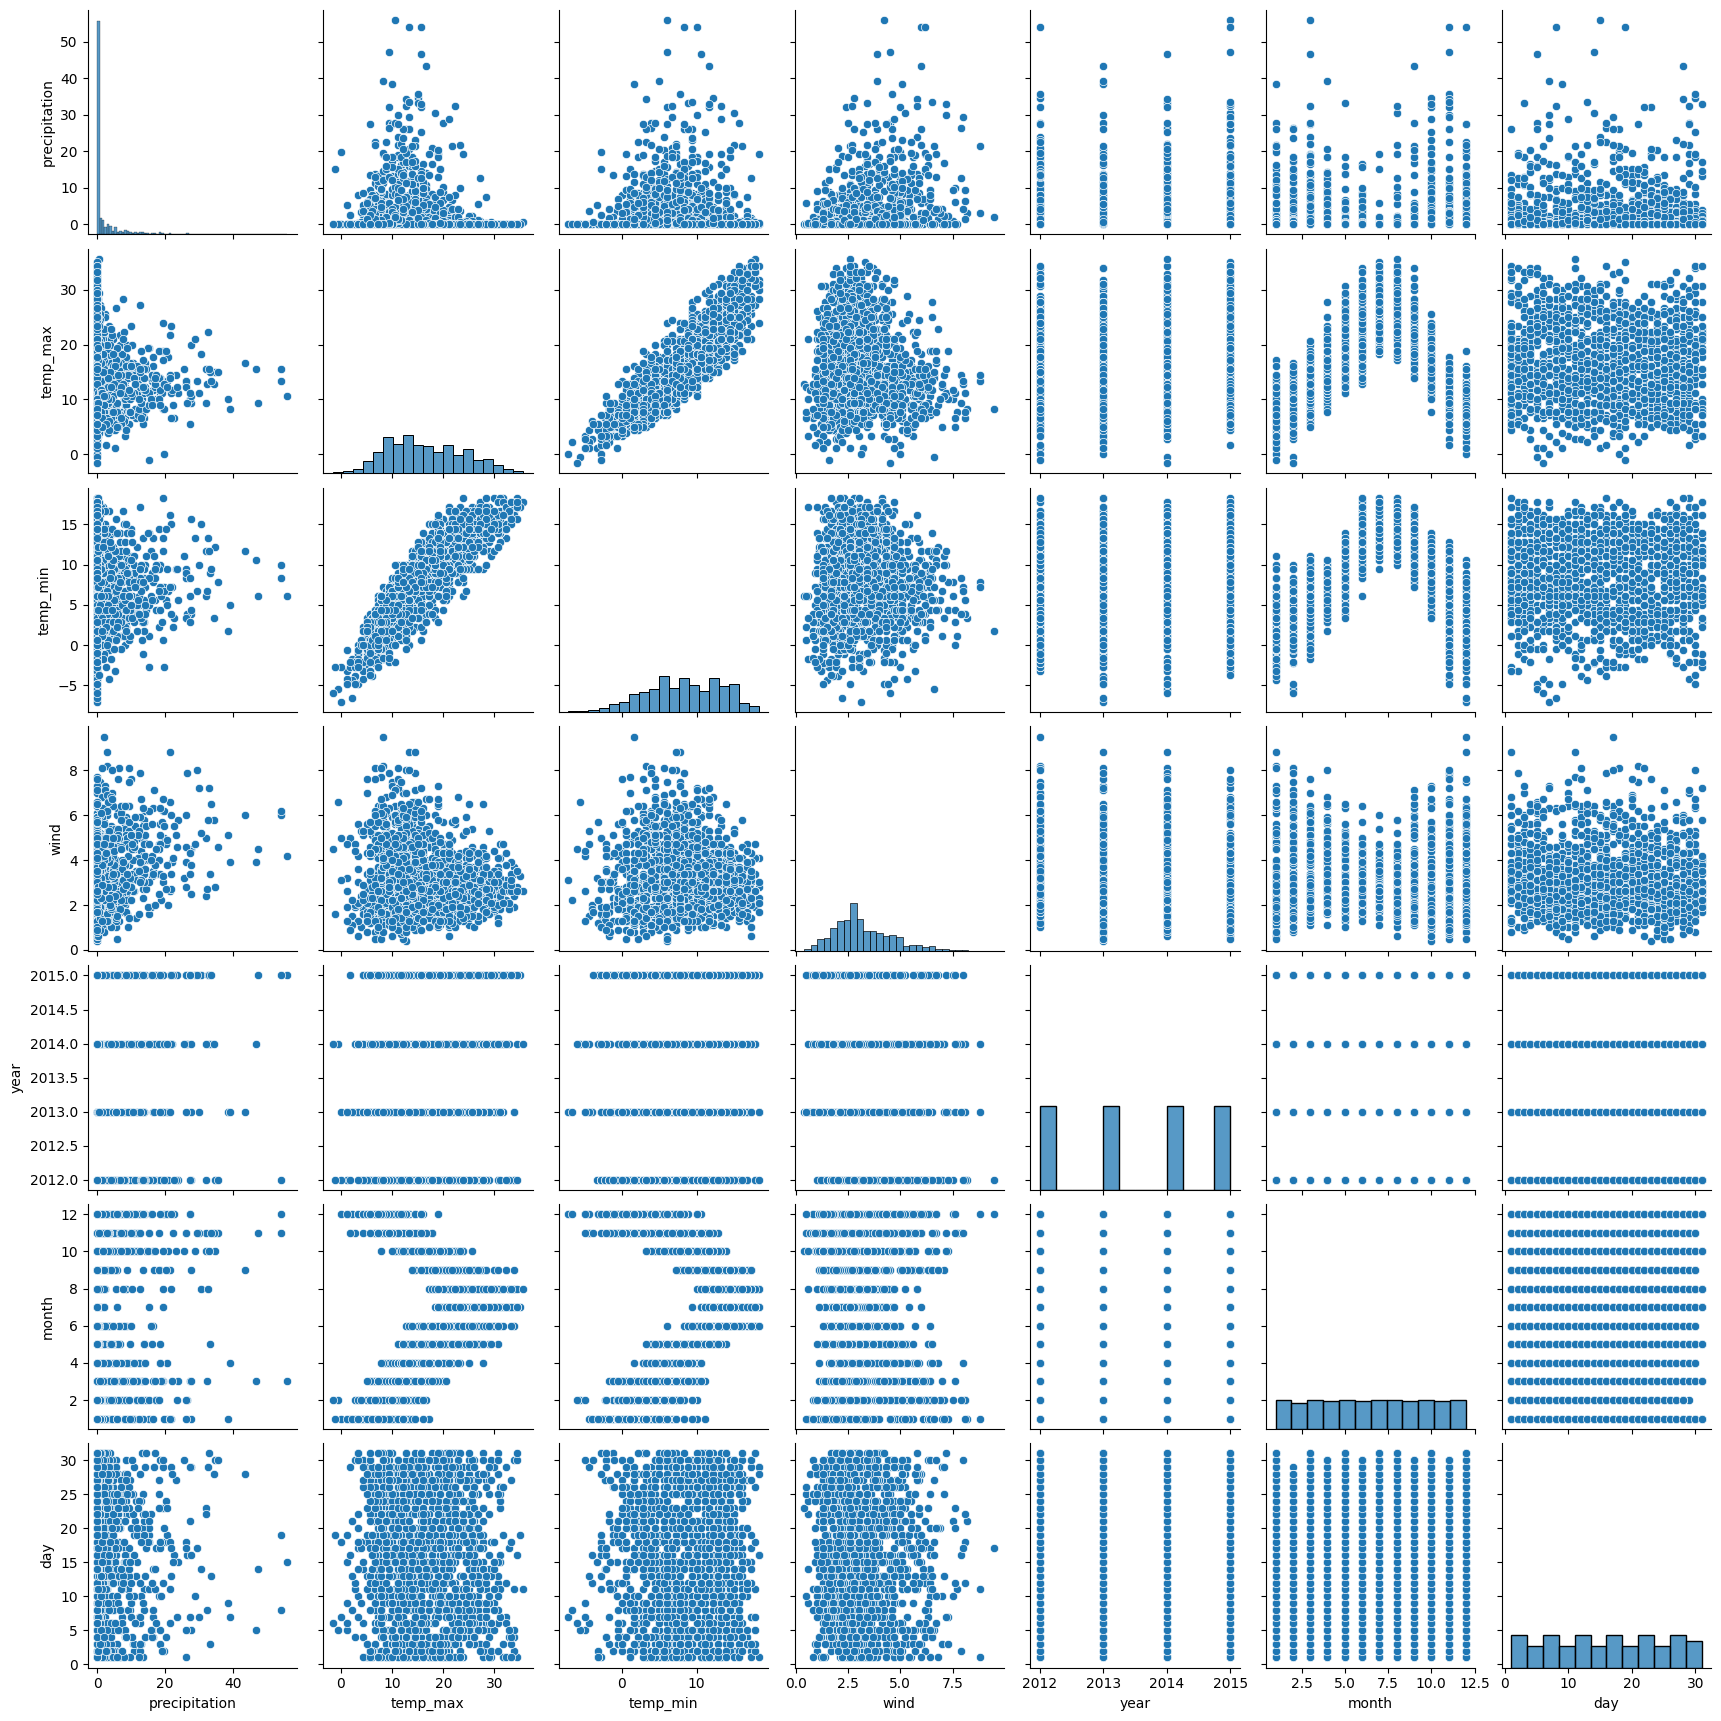

In [90]:
plt.figure(figsize=(6,10))
sns.pairplot(df)

In [91]:
df.dtypes

,0
precipitation,float64
temp_max,float64
temp_min,float64
wind,float64
weather,object
year,int32
month,int32
day,int32


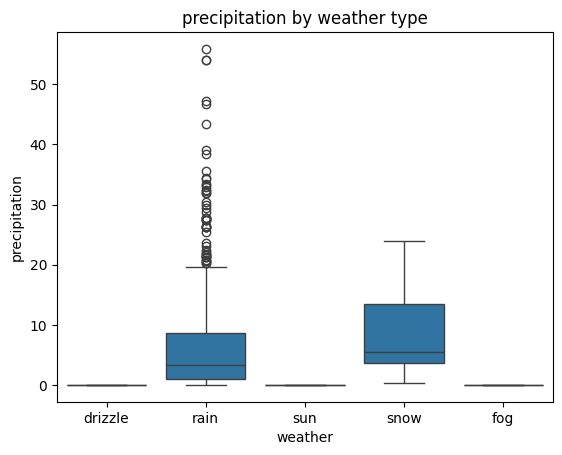

In [92]:
sns.boxplot(x='weather', y='precipitation', data=df)
plt.title('precipitation by weather type')
plt.show()

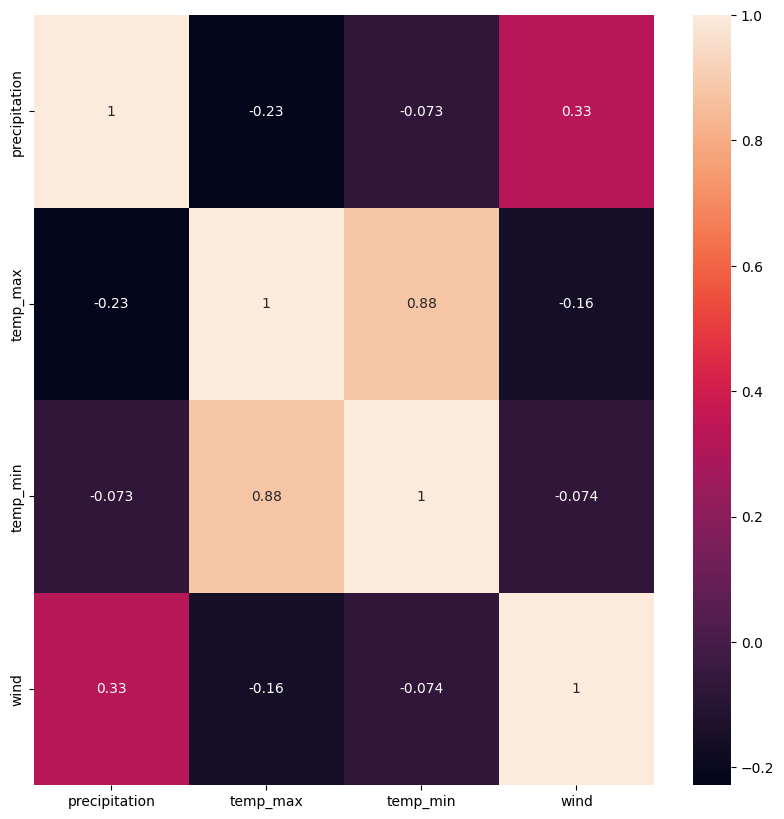

In [93]:
plt.figure(figsize=(10,10))
sns.heatmap(df.select_dtypes(include=['float64', 'int64']).corr(), annot=True)
plt.show()

Temp Min was not that relevant to the prediction as shown in the correlation heatmap


In [94]:
df = df.drop(columns=['temp_min'])

X takes everything but the 'weather' column and y only gets the 'weather' column

In [95]:
x = df.drop(['weather'], axis = 1)
y = df['weather']

I splited the values to train


In [96]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=43, shuffle=False)

In [97]:
x_train.shape, x_test.shape, y_train.shape, y_test.shape

((1168, 6), (293, 6), (1168,), (293,))

Encoded the 'weather' column as it was an object and cant be directly converted to float64  

In [98]:
lb = LabelEncoder()
y_encoded = lb.fit_transform(y)

In [99]:
rf = RandomForestClassifier()
rf.fit(x_train, y_train)

RandomForestClassifier()

In [100]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1461 entries, 0 to 1460
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   precipitation  1461 non-null   float64
 1   temp_max       1461 non-null   float64
 2   wind           1461 non-null   float64
 3   weather        1461 non-null   object 
 4   year           1461 non-null   int32  
 5   month          1461 non-null   int32  
 6   day            1461 non-null   int32  
dtypes: float64(3), int32(3), object(1)
memory usage: 62.9+ KB


In [101]:
y_pred = rf.predict(x_test)

accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy}')

Accuracy: 0.856655290102389


In [102]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

     drizzle       0.00      0.00      0.00         7
         fog       0.20      0.03      0.06        31
        rain       1.00      0.99      1.00       110
        snow       0.00      0.00      0.00         0
         sun       0.79      0.97      0.87       145

    accuracy                           0.86       293
   macro avg       0.40      0.40      0.38       293
weighted avg       0.79      0.86      0.81       293



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_

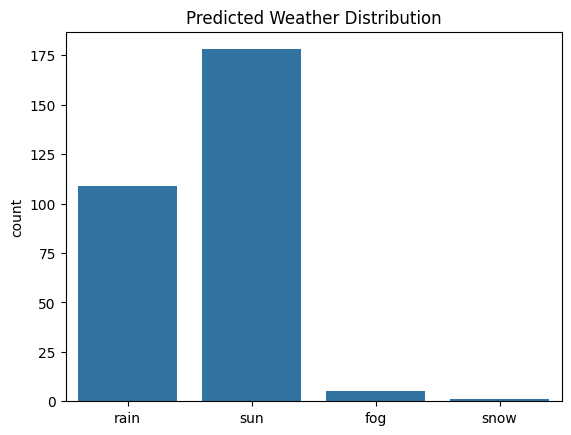

In [103]:
plt.figure(figsize=(6.4, 4.8))
sns.countplot(x=y_pred)
plt.title('Predicted Weather Distribution')
plt.show()

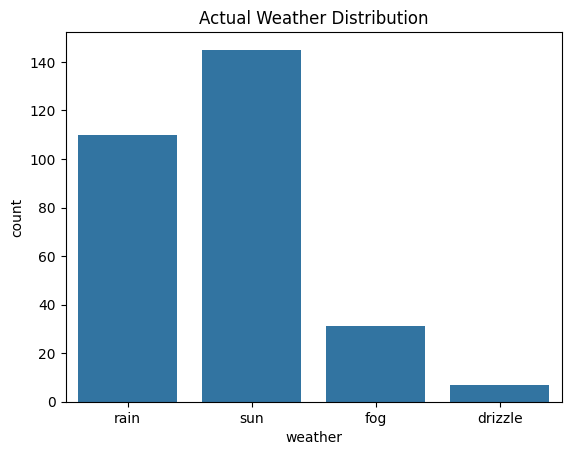

In [104]:
sns.countplot(x=y_test)
plt.title('Actual Weather Distribution')
plt.show()

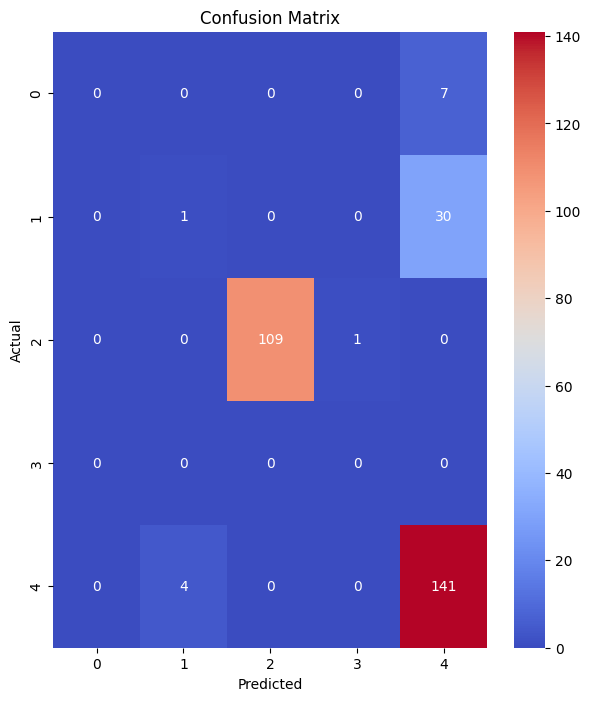

In [105]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7,8))
sns.heatmap(cm, annot=True, fmt='d', cmap='coolwarm')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

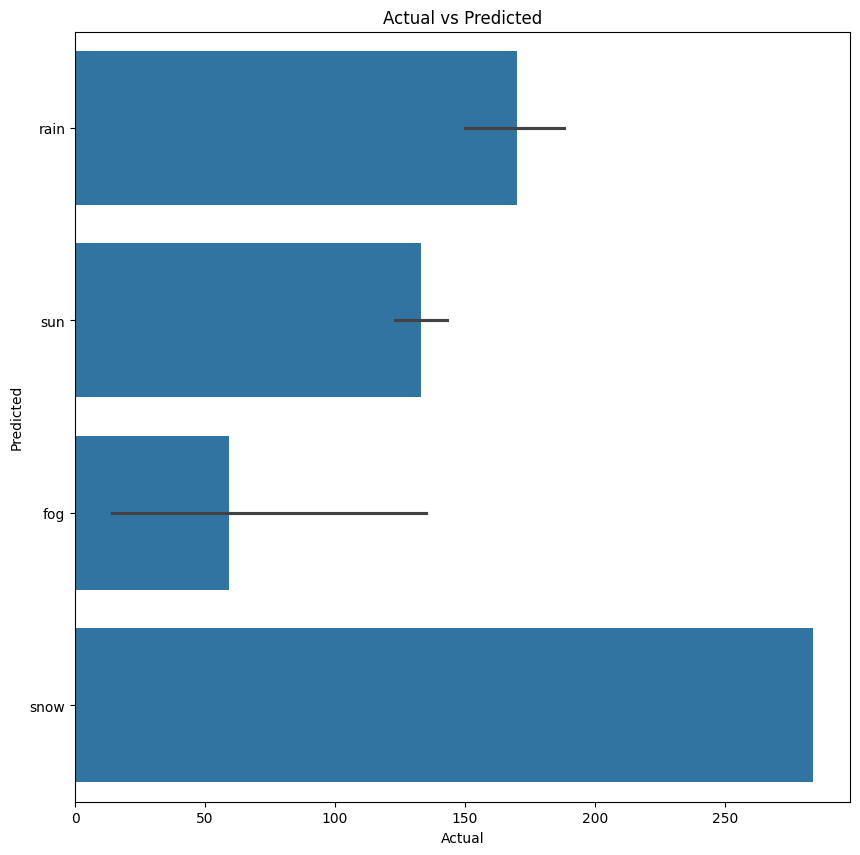

In [106]:
# JUST TO TEST/EXPLORE

plt.figure(figsize=(10,10))
sns.barplot(y_pred)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Actual vs Predicted')
plt.show()

In [107]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train, y_train)

y_pred_knn = knn.predict(x_test)


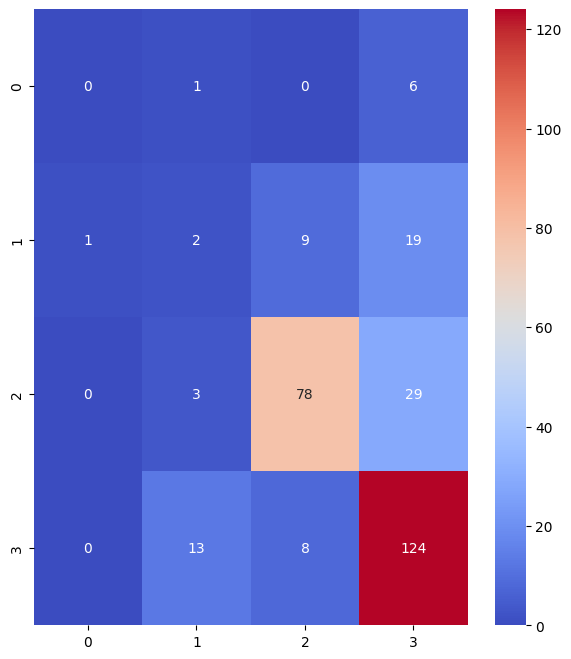

In [108]:
cm = confusion_matrix(y_test, y_pred_knn)
plt.figure(figsize=(7,8))
sns.heatmap(cm, annot=True, fmt='d', cmap='coolwarm')
plt.show()

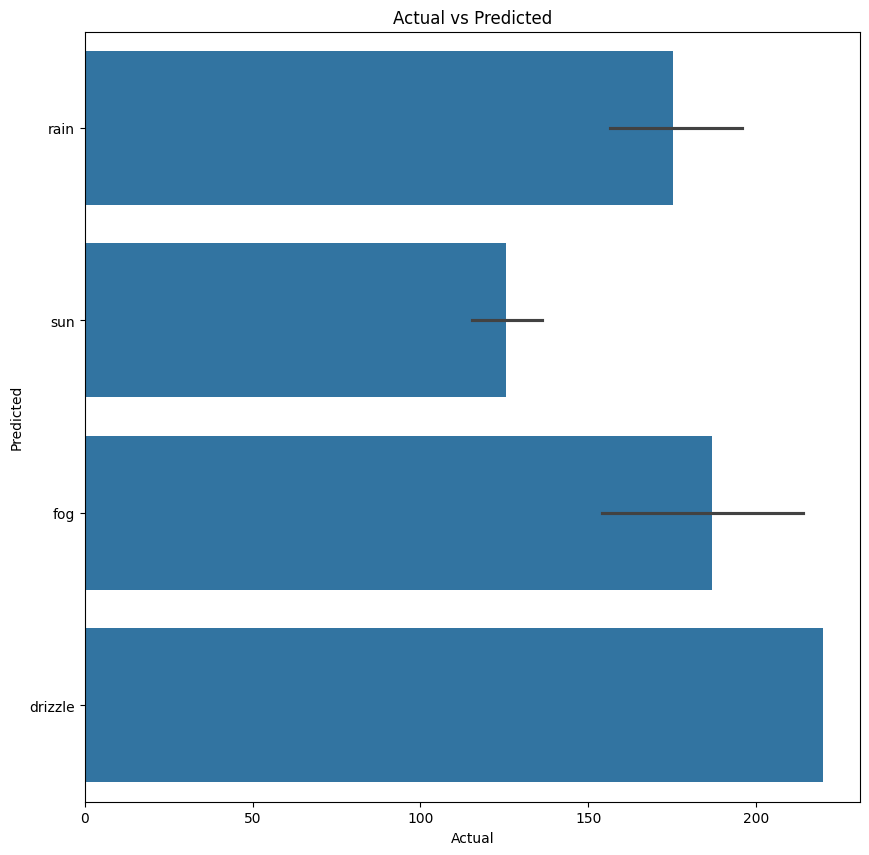

In [109]:
plt.figure(figsize=(10,10))
sns.barplot(y_pred_knn)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Actual vs Predicted')
plt.show()

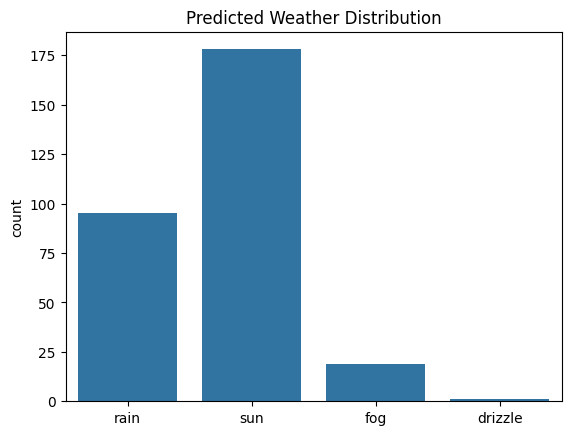

In [110]:
plt.figure(figsize=(6.4, 4.8))
sns.countplot(x=y_pred_knn)
plt.title('Predicted Weather Distribution')
plt.show()